**ESOPHAGEAL CANCER CLASSIFICATION USING LOGISTIC REGRESSION FOR SAVE IMAGES**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression  # Import Logistic Regression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [3]:
# Constants
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS = 3

In [4]:
import tensorflow as tf
import numpy as np

# Define the paths
train_dir = '/content/drive/MyDrive/Arvind/Arvind/combined_split/train'
val_dir = '/content/drive/MyDrive/Arvind/Arvind/combined_split/val'
test_dir = '/content/drive/MyDrive/Arvind/Arvind/combined_split/test'

# Function to load and flatten the dataset
def load_and_flatten_data(directory, image_size=(640, 640), batch_size=32):
    # Load images from the directory
    dataset = tf.keras.preprocessing.image_dataset_from_directory(
        directory,
        image_size=image_size,
        batch_size=batch_size,
        shuffle=True
    )

    # Flatten the images and extract labels
    flat_data = []
    target_data = []
    for image_batch, labels_batch in dataset:
        for img, label in zip(image_batch, labels_batch):
            img_array = img.numpy().astype('uint8')  # Convert image to NumPy array
            img_flattened = img_array.flatten()      # Flatten the image
            flat_data.append(img_flattened)          # Append flattened image to the list
            target_data.append(label.numpy())        # Append label to the list

    return np.array(flat_data), np.array(target_data)

# Load and flatten each dataset
train_flat_data, train_labels = load_and_flatten_data(train_dir)
val_flat_data, val_labels = load_and_flatten_data(val_dir)
test_flat_data, test_labels = load_and_flatten_data(test_dir)

# Now you can use these flattened datasets for logistic regression


Found 8960 files belonging to 14 classes.
Found 2560 files belonging to 14 classes.
Found 320 files belonging to 14 classes.


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Assign the flattened data to X and y variables for clarity
X_train, y_train = train_flat_data, train_labels
X_val, y_val = val_flat_data, val_labels
X_test, y_test = test_flat_data, test_labels

# Initialize the Logistic Regression model
logistic_model = LogisticRegression(max_iter=10000)  # Increase max_iter if convergence issues arise

# Train the model on the training data
logistic_model.fit(X_train, y_train)

# Evaluate the model on the validation data
y_val_pred = logistic_model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)
print(f'Validation Accuracy: {val_accuracy:.2f}')

# Evaluate the model on the test data
y_test_pred = logistic_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f'Test Accuracy: {test_accuracy:.2f}')

# Generate a classification report
print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

# Generate a confusion matrix
print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))


Validation Accuracy: 0.52
Test Accuracy: 0.49

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.31      0.40      0.35        20
           1       0.35      0.30      0.32        20
           2       0.41      0.28      0.33        25
           3       0.29      0.32      0.30        25
           4       0.56      0.45      0.50        20
           5       0.58      0.70      0.64        10
           6       0.46      0.60      0.52        20
           7       0.50      0.60      0.55        20
           8       0.58      0.47      0.52        40
           9       0.48      0.50      0.49        40
          10       0.67      0.60      0.63        20
          11       0.50      0.50      0.50        20
          12       0.79      0.55      0.65        20
          13       0.59      0.80      0.68        20

    accuracy                           0.49       320
   macro avg       0.50      0.51      0.50       3

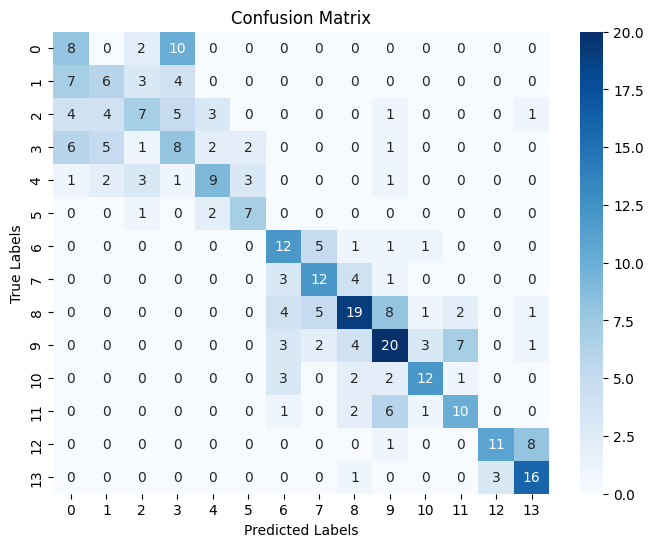

In [6]:
# Assuming 'y_test' and 'y_test_pred' are defined from the previous code
cm = confusion_matrix(y_test, y_test_pred)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


In [7]:
class_names = os.listdir(train_dir)
for index, class_name in enumerate(class_names):
  print(f"Class index: {index}, Class name: {class_name}")


Class index: 0, Class name: w5.ec
Class index: 1, Class name: w6.ero
Class index: 2, Class name: w8.s
Class index: 3, Class name: w7.d
Class index: 4, Class name: w1.n
Class index: 5, Class name: w3.ca
Class index: 6, Class name: w4.ev
Class index: 7, Class name: w2.dys
Class index: 8, Class name: n6.ero
Class index: 9, Class name: n3.ca
Class index: 10, Class name: n2.dys
Class index: 11, Class name: n4.ev
Class index: 12, Class name: n5.ec
Class index: 13, Class name: n1.n


In [8]:
class_names = os.listdir(train_dir)
for index, class_name in enumerate(class_names):
  print(f"{class_name}")

w5.ec
w6.ero
w8.s
w7.d
w1.n
w3.ca
w4.ev
w2.dys
n6.ero
n3.ca
n2.dys
n4.ev
n5.ec
n1.n


In [9]:
# Assuming 'train_dir' is the directory containing subdirectories for each class
class_names = os.listdir(train_dir)

for index, class_name in enumerate(class_names):
  print(f"Index: {index}, Class Name: {class_name}")


Index: 0, Class Name: w5.ec
Index: 1, Class Name: w6.ero
Index: 2, Class Name: w8.s
Index: 3, Class Name: w7.d
Index: 4, Class Name: w1.n
Index: 5, Class Name: w3.ca
Index: 6, Class Name: w4.ev
Index: 7, Class Name: w2.dys
Index: 8, Class Name: n6.ero
Index: 9, Class Name: n3.ca
Index: 10, Class Name: n2.dys
Index: 11, Class Name: n4.ev
Index: 12, Class Name: n5.ec
Index: 13, Class Name: n1.n


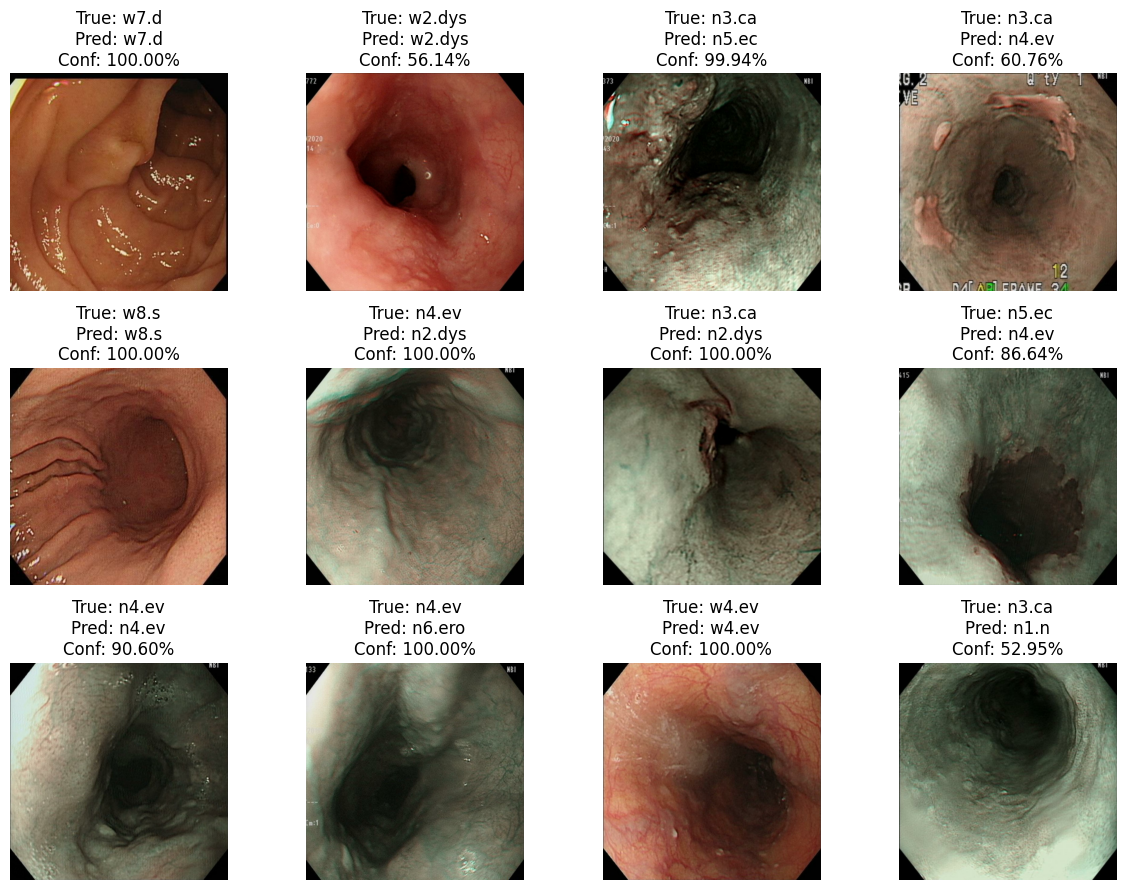

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming you have already loaded your test dataset and logistic model

# Make predictions and get prediction probabilities for the test dataset
y_test_pred = logistic_model.predict(X_test)  # Predicted labels
y_test_prob = logistic_model.predict_proba(X_test)  # Probabilities of each class

# Function to display images with predictions and confidence
def display_predictions(images, true_labels, predicted_labels, probabilities, class_names, num_images=12):
    plt.figure(figsize=(12, 9))  # Set the figure size
    for i in range(num_images):
        plt.subplot(3, 4, i + 1)  # 3x4 grid for displaying 12 images
        img = images[i].reshape(640, 640, 3)  # Reshape flat image back to 3D (adjust according to image size)
        plt.imshow(img)
        true_label = class_names[true_labels[i]]
        predicted_label = class_names[predicted_labels[i]]
        confidence = np.max(probabilities[i]) * 100  # Highest probability as confidence score
        plt.title(f"True: {true_label}\nPred: {predicted_label}\nConf: {confidence:.2f}%")
        plt.axis('off')  # Turn off axis

    plt.tight_layout()
    plt.show()

# Assuming you have your class names available
class_names = ['n1.n', 'n2.dys', 'n3.ca', 'n4.ev', 'n5.ec', 'n6.ero', 'w1.n', 'w2.dys','w3.ca', 'w4.ev','w5.ec', 'w6.ero', 'w7.d', 'w8.s']  # Replace with your actual class names

# Display 12 predictions
display_predictions(test_flat_data, y_test, y_test_pred, y_test_prob, class_names, num_images=12) # Changed test_images to test_flat_data

In [11]:
import joblib
# Save the trained Logistic Regression model to your working directory
joblib.dump(logistic_model, '/content/drive/MyDrive/Arvind/logistic_regression_model.pkl')


['/content/drive/MyDrive/Arvind/logistic_regression_model.pkl']